Importa as bibliotecas necessárias e lê o arquivo de dados.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

arquivo = "dados.xlsx"
df = pd.read_excel(arquivo)
df.head()


,ID_Ensaio,Data_Hora,Tipo_Motor,Estrategia_Controle,Inversor,Nivel_Carga,Ganho_Kp,Ganho_Ki,Setpoint_Rotacao_rpm,Rotacao_Medida_rpm,Erro_Rotacao_rpm,Tensao_Linha_V,Corrente_A,Potencia_Ativa_kW,Fator_Potencia,THD_Corrente_Perc,Temperatura_Enrolamento_C,Vibracao_mm_s,Tempo_Resposta_ms,Status_Alarme
0,EN-00001,2025-05-22 06:19:00,Síncrono PM,Controle vetorial,Inversor B,Leve,1.371,0.542,1800,1771.4,-28.6,389.5,7.20,4.17,0.858,7.20,59.5,2.07,87.1,Normal
1,EN-00002,2025-07-23 16:21:00,Relutância síncrona,Controle vetorial,Inversor B,Pesada,1.775,0.610,2400,2385.1,-14.9,382.7,19.30,12.24,0.957,5.42,83.4,2.15,119.4,Normal
2,EN-00003,2025-03-15 13:20:00,Indução trifásico,Controle vetorial,Inversor B,Pesada,1.406,0.587,900,884.2,-15.8,364.6,11.14,6.32,0.899,5.39,84.9,3.03,106.4,Normal
3,EN-00004,2025-09-29 15:55:00,Síncrono PM,DTC,Inversor A,Sobrecarga,2.036,0.586,1500,1492.5,-7.5,397.1,17.65,12.02,0.990,5.86,93.3,2.29,59.7,Alerta
4,EN-00005,2025-12-31 19:12:00,Indução trifásico,Controle vetorial,Inversor B,Média,1.530,0.604,1800,1789.8,-10.2,368.6,12.91,6.87,0.834,7.32,66.8,2.37,134.4,Normal


Para visualizar o início dos dados e ter uma ideia do que estamos trabalhando.


In [ ]:
niveis_corrente = df['Corrente_A']
niveis_corrente.describe()


count    1050.000000
mean       14.199800
std         5.752109
min         3.760000
25%         9.790000
50%        13.325000
75%        17.465000
max        34.540000
Name: Corrente_A, dtype: float64

Os valores de corrente foram agrupados em classes para facilitar a visualização. A tabela abaixo reúne a frequência absoluta, a frequência absoluta acumulada, a frequência percentual e a frequência percentual acumulada.


In [ ]:
grupos = [3.75, 5, 10, 15, 20, 25, 30, 35]
freq_abs = pd.cut(niveis_corrente, grupos).value_counts().sort_index()
freq_abs.name = 'Frequência Absoluta'

freq_abs_acumulada = freq_abs.cumsum()
freq_percentual = (freq_abs / freq_abs.sum()) * 100
freq_percentual_acumulada = freq_percentual.cumsum()

tabela_freq = pd.DataFrame({
    'Frequência Absoluta': freq_abs,
    'Frequência Absoluta Acumulada': freq_abs_acumulada,
    'Frequência Percentual (%)': freq_percentual.round(2),
    'Frequência Percentual Acumulada (%)': freq_percentual_acumulada.round(2)
})

tabela_freq


,Frequência Absoluta,Frequência Absoluta Acumulada,Frequência Percentual (%),Frequência Percentual Acumulada (%)
Corrente_A,,,,
"(3.75, 5.0]",18,18,1.71,1.71
"(5.0, 10.0]",264,282,25.14,26.86
"(10.0, 15.0]",357,639,34.00,60.86
"(15.0, 20.0]",253,892,24.10,84.95
"(20.0, 25.0]",100,992,9.52,94.48
"(25.0, 30.0]",48,1040,4.57,99.05
"(30.0, 35.0]",10,1050,0.95,100.00


Gráfico de barras da frequência absoluta e da frequência percentual por classe de corrente, com título e eixos identificados.


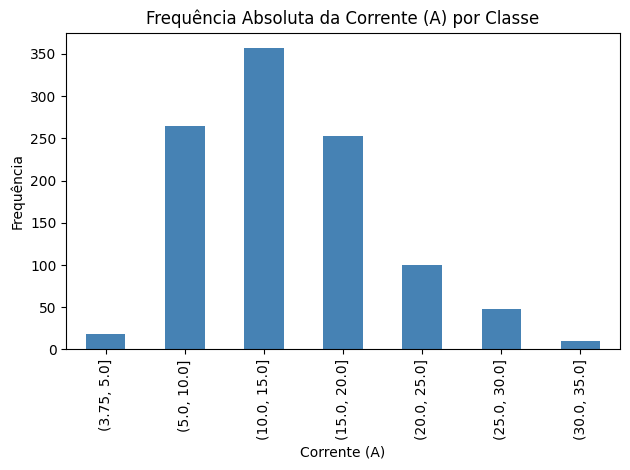

In [ ]:
tabela_freq['Frequência Absoluta'].plot(kind='bar', color='steelblue')
plt.title('Frequência Absoluta da Corrente (A) por Classe')
plt.xlabel('Corrente (A)')
plt.ylabel('Frequência')
plt.tight_layout()
plt.show()


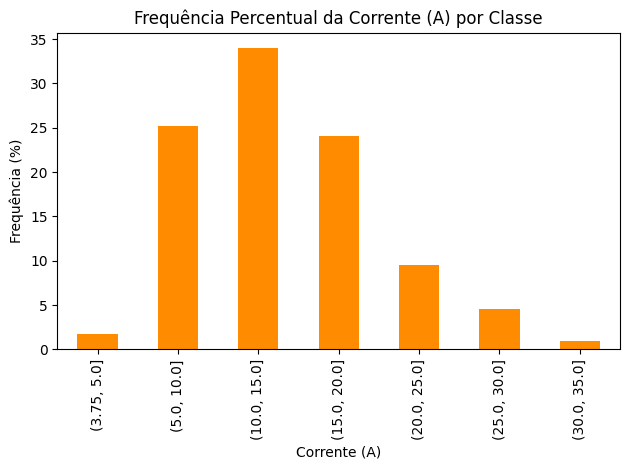

In [ ]:
tabela_freq['Frequência Percentual (%)'].plot(kind='bar', color='darkorange')
plt.title('Frequência Percentual da Corrente (A) por Classe')
plt.xlabel('Corrente (A)')
plt.ylabel('Frequência (%)')
plt.tight_layout()
plt.show()


Cálculo das principais medidas de tendência central para a variável Corrente (A).


In [ ]:
media = df['Corrente_A'].mean()
mediana = df['Corrente_A'].median()
moda = df['Corrente_A'].mode()

print(f'Média: {media:.2f} A')
print(f'Mediana: {mediana:.2f} A')
print('Moda:')
display(moda)


Média: 14.20 A
Mediana: 13.32 A
Moda:


0     7.63
1    12.17
Name: Corrente_A, dtype: float64

**Interpretação:** a corrente elétrica média registrada nos ensaios é de aproximadamente **14,20 A**, com mediana de **13,32 A** — valores próximos, o que sugere uma distribuição razoavelmente simétrica, sem grandes distorções causadas por valores extremos. A moda é bimodal (7,63 A e 12,17 A), o que é coerente com o fato de os ensaios cobrirem diferentes estratégias de controle e níveis de carga dos motores, gerando mais de um regime típico de operação.
